# Sales Prediciton with Simple Linear Regression

## Data

**Problem Statement**

Build a model which predicts sales based on the money spent on different platforms for marketing.


**Data**

Use the advertising dataset given in ISLR and analyse the relationship between 'TV advertising' and 'sales' using a simple linear regression model.


**Link Dataset :**

https://www.kaggle.com/datasets/mahmoudshaheen1134/sales-and-advertising-clean-dataset

## LINEAR REGRESSION


## Import Library

In [ ]:
# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import LabelEncoder


import warnings
warnings.filterwarnings('ignore')

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Load data

## Data Understanding

In [ ]:
df = pd.DataFrame(pd.read_csv("/content/drive/MyDrive/SI DATA SCIENTIST CAKAP/advertising_and_sales_clean.csv"))
df.head()

,tv,radio,social_media,influencer,sales
0,16000.0,6566.23,2907.98,Mega,54732.76
1,13000.0,9237.76,2409.57,Mega,46677.90
2,41000.0,15886.45,2913.41,Mega,150177.83
3,83000.0,30020.03,6922.30,Mega,298246.34
4,15000.0,8437.41,1406.00,Micro,56594.18


In [ ]:
df.shape

(4546, 5)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4546 entries, 0 to 4545
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   tv            4546 non-null   float64
 1   radio         4546 non-null   float64
 2   social_media  4546 non-null   float64
 3   influencer    4546 non-null   object 
 4   sales         4546 non-null   float64
dtypes: float64(4), object(1)
memory usage: 177.7+ KB


In [ ]:
df.describe()

,tv,radio,social_media,sales
count,4546.000000,4546.000000,4546.000000,4546.000000
mean,54062.912451,18157.533110,3323.472829,192413.332112
std,26104.941838,9663.259642,2211.253915,93019.873216
min,10000.000000,0.680000,0.030000,31199.410000
25%,32000.000000,10555.355000,1530.822500,112434.610000
50%,53000.000000,17859.515000,3055.565000,188963.680000
75%,77000.000000,25640.605000,4804.922500,272324.240000
max,100000.000000,48871.160000,13981.660000,364079.750000


In [ ]:
df.isnull().sum()

,0
tv,0
radio,0
social_media,0
influencer,0
sales,0


## Data Cleansing

In [ ]:
# Check null value
df.isnull().sum()*100/df.shape[0]

,0
tv,0.0
radio,0.0
social_media,0.0
influencer,0.0
sales,0.0


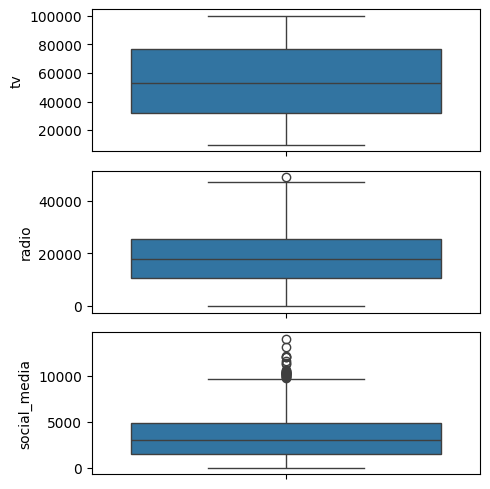

In [ ]:
# Outlier Analysis
fig, axs = plt.subplots(3, figsize = (5,5))
plt1 = sns.boxplot(df['tv'], ax = axs[0])
plt2 = sns.boxplot(df['radio'], ax = axs[1])
plt3 = sns.boxplot(df['social_media'], ax = axs[2])
plt.tight_layout()

## EDA

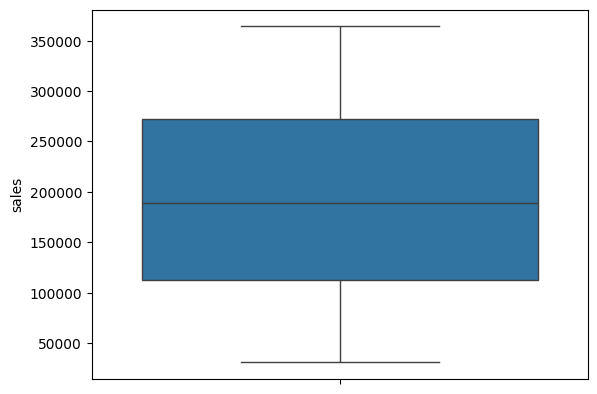

In [ ]:
# Univariate Analysis

sns.boxplot(df['sales'])
plt.show()

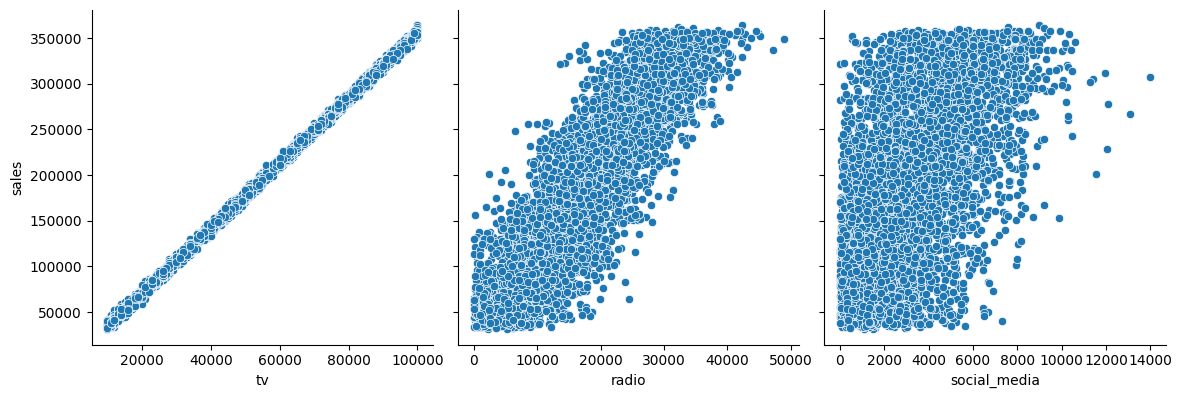

In [ ]:
# Sales are related with other variables using scatter plot.

sns.pairplot(df, x_vars=['tv', 'radio', 'social_media'], y_vars='sales', height=4, aspect=1, kind='scatter')
plt.show()

In [ ]:
df['influencer'] = df['influencer'].map({'Mega': 2, 'Micro': 1, 'Nano': 0})
df['influencer'] = df['influencer'].astype(float)

In [ ]:
label_encoder = LabelEncoder()


df['influencer'] = label_encoder.fit_transform(df['influencer'])


df.drop(columns=['influencer'], inplace=True)

print(df.head())

        tv     radio  social_media      sales
0  16000.0   6566.23       2907.98   54732.76
1  13000.0   9237.76       2409.57   46677.90
2  41000.0  15886.45       2913.41  150177.83
3  83000.0  30020.03       6922.30  298246.34
4  15000.0   8437.41       1406.00   56594.18


In [ ]:
print("Distribution of categorical variables:")
cat_cols = df.select_dtypes(include=['object']).columns
for col in cat_cols:
    print(f"Column: {col}")
    print(df[col].value_counts())
    print()

Distribution of categorical variables:


In [ ]:
print("Distribution of numerical variables:")
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
for col in num_cols:
    print(f"Column: {col}")
    print(df[col].describe())
    print()

Distribution of numerical variables:
Column: tv
count      4546.000000
mean      54062.912451
std       26104.941838
min       10000.000000
25%       32000.000000
50%       53000.000000
75%       77000.000000
max      100000.000000
Name: tv, dtype: float64

Column: radio
count     4546.000000
mean     18157.533110
std       9663.259642
min          0.680000
25%      10555.355000
50%      17859.515000
75%      25640.605000
max      48871.160000
Name: radio, dtype: float64

Column: social_media
count     4546.000000
mean      3323.472829
std       2211.253915
min          0.030000
25%       1530.822500
50%       3055.565000
75%       4804.922500
max      13981.660000
Name: social_media, dtype: float64

Column: sales
count      4546.000000
mean     192413.332112
std       93019.873216
min       31199.410000
25%      112434.610000
50%      188963.680000
75%      272324.240000
max      364079.750000
Name: sales, dtype: float64



In [ ]:
# find numerical variables

numerical = [var for var in df.columns if df[var].dtype!='O']

print('There are {} numerical variables\n'.format(len(numerical)))

print('The numerical variables are :', numerical)

There are 4 numerical variables

The numerical variables are : ['tv', 'radio', 'social_media', 'sales']


In [ ]:
df[numerical].head()

,tv,radio,social_media,sales
0,16000.0,6566.23,2907.98,54732.76
1,13000.0,9237.76,2409.57,46677.90
2,41000.0,15886.45,2913.41,150177.83
3,83000.0,30020.03,6922.30,298246.34
4,15000.0,8437.41,1406.00,56594.18


In [ ]:
df[numerical].isnull().sum()

,0
tv,0
radio,0
social_media,0
sales,0


Text(0, 0.5, 'Sales')

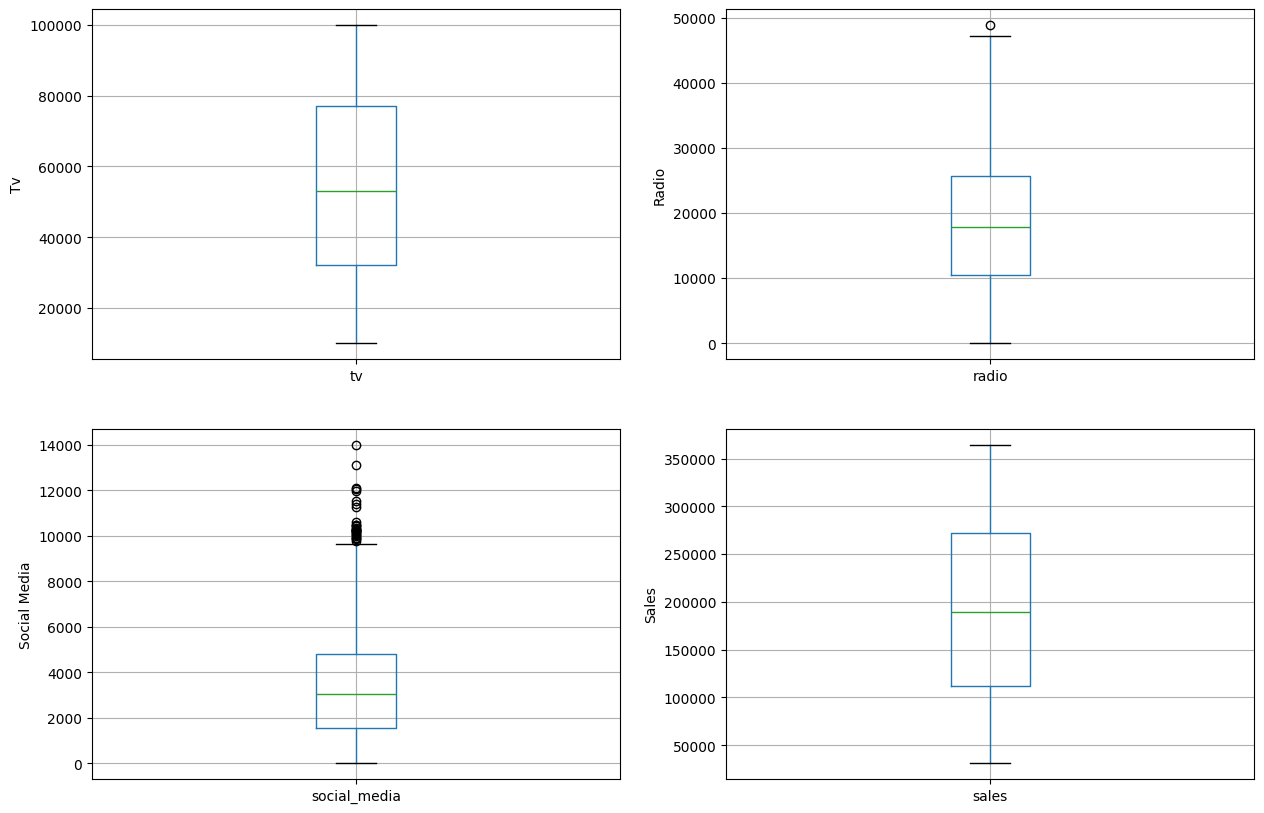

In [ ]:
plt.figure(figsize=(15,10))


plt.subplot(2, 2, 1)
fig = df.boxplot(column='tv')
fig.set_title('')
fig.set_ylabel('Tv')


plt.subplot(2, 2, 2)
fig = df.boxplot(column='radio')
fig.set_title('')
fig.set_ylabel('Radio')


plt.subplot(2, 2, 3)
fig = df.boxplot(column='social_media')
fig.set_title('')
fig.set_ylabel('Social Media')

plt.subplot(2, 2, 4)
fig = df.boxplot(column='sales')
fig.set_title('')
fig.set_ylabel('Sales')

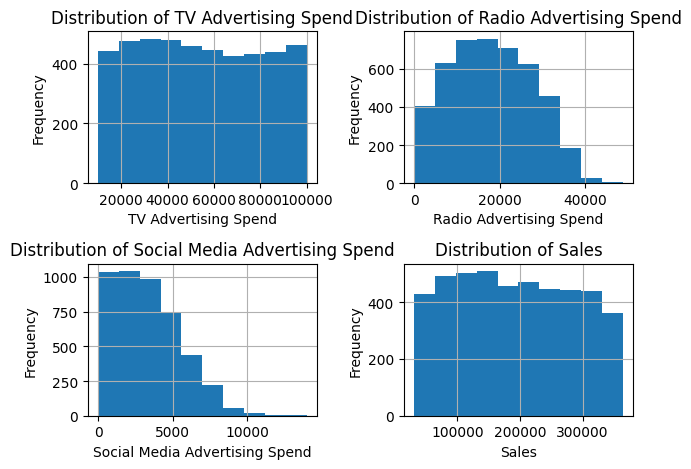

In [ ]:
# Histogram untuk kolom 'tv'
plt.subplot(2, 2, 1)
df['tv'].hist(bins=10)
plt.xlabel('TV Advertising Spend')
plt.ylabel('Frequency')
plt.title('Distribution of TV Advertising Spend')

# Histogram untuk kolom 'radio'
plt.subplot(2, 2, 2)
df['radio'].hist(bins=10)
plt.xlabel('Radio Advertising Spend')
plt.ylabel('Frequency')
plt.title('Distribution of Radio Advertising Spend')

# Histogram untuk kolom 'social_media'
plt.subplot(2, 2, 3)
df['social_media'].hist(bins=10)
plt.xlabel('Social Media Advertising Spend')
plt.ylabel('Frequency')
plt.title('Distribution of Social Media Advertising Spend')

# Histogram untuk kolom 'sales'
plt.subplot(2, 2, 4)
df['sales'].hist(bins=10)
plt.xlabel('Sales')
plt.ylabel('Frequency')
plt.title('Distribution of Sales')

# Menyesuaikan layout dan menampilkan plot
plt.tight_layout()
plt.show()

In [ ]:
# Find IQR

IQR = df.tv.quantile(0.75) - df.tv.quantile(0.25)
Lower_fence = df.tv.quantile(0.25) - (IQR * 3)
Upper_fence = df.tv.quantile(0.75) + (IQR * 3)
print('tv outliers are values < {lowerboundary} or > {upperboundary}'.format(lowerboundary=Lower_fence, upperboundary=Upper_fence))

tv outliers are values < -103000.0 or > 212000.0


In [ ]:
# Find IQR

IQR = df.radio.quantile(0.75) - df.radio.quantile(0.25)
Lower_fence = df.radio.quantile(0.25) - (IQR * 3)
Upper_fence = df.radio.quantile(0.75) + (IQR * 3)
print('radio outliers are values < {lowerboundary} or > {upperboundary}'.format(lowerboundary=Lower_fence, upperboundary=Upper_fence))

radio outliers are values < -34700.395000000004 or > 70896.355


In [ ]:
# Find IQR

IQR = df.social_media.quantile(0.75) - df.social_media.quantile(0.25)
Lower_fence = df.social_media.quantile(0.25) - (IQR * 3)
Upper_fence = df.social_media.quantile(0.75) + (IQR * 3)
print('social media outliers are values < {lowerboundary} or > {upperboundary}'.format(lowerboundary=Lower_fence, upperboundary=Upper_fence))

social media outliers are values < -8291.477499999999 or > 14627.2225


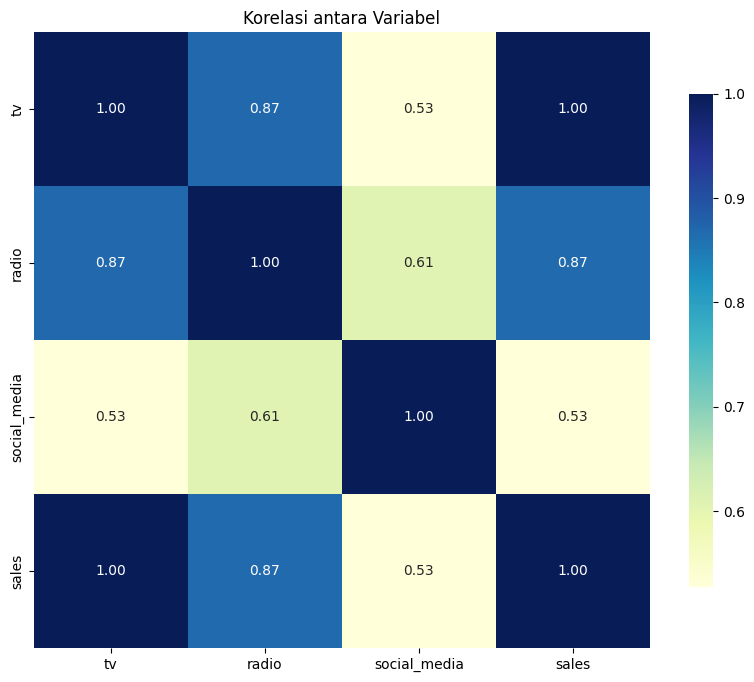

In [ ]:
# Hitung matriks korelasi
correlation_matrix = df.corr()

# Buat heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, cmap="YlGnBu", annot=True, fmt=".2f", square=True, cbar_kws={"shrink": .8})

# Tampilkan plot
plt.title('Korelasi antara Variabel')
plt.show()

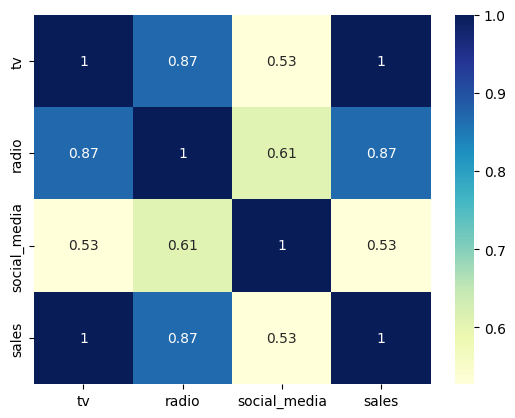

In [ ]:
# correlation between different variables.
sns.heatmap(df.corr(), cmap="YlGnBu", annot = True)
plt.show()

**Interpretation:**

The variable TV seems to be most correlated with Sales. So let's go ahead and perform simple linear regression using TV as our feature variable

## Linear Regression


## Build Model Statsmodel

We first assign the feature variable, TV, in this case, to the variable X and the response variable, Sales, to the variable y.

In [ ]:
X = df['tv']
y = df['sales']

Train-Test Split

It is usually a good practice to keep 70% of the data in your train dataset and the rest 30% in your test dataset

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size = 0.7, test_size = 0.3, random_state = 100)

In [ ]:
X_train.head()

,tv
4041,72000.0
883,50000.0
2366,83000.0
3668,33000.0
3205,63000.0


In [ ]:
y_train.head()

,sales
4041,257845.96
883,173853.69
2366,295456.39
3668,113396.52
3205,230124.35


In [ ]:
# Add a constant to get an intercept
X_train_sm = sm.add_constant(X_train)

# Fit the resgression line using 'OLS'
lr = sm.OLS(y_train, X_train_sm).fit()

In [ ]:
# intercept and the slope of the regression line fitted
lr.params

,0
const,-111.057850
tv,3.560633


In [ ]:
# summary operation lists out all the different parameters of the regression line fitted
print(lr.summary())

                            OLS Regression Results                            
Dep. Variable:                  sales   R-squared:                       0.999
Model:                            OLS   Adj. R-squared:                  0.999
Method:                 Least Squares   F-statistic:                 3.282e+06
Date:                Sat, 23 Nov 2024   Prob (F-statistic):               0.00
Time:                        09:15:04   Log-Likelihood:                -29891.
No. Observations:                3182   AIC:                         5.979e+04
Df Residuals:                    3180   BIC:                         5.980e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -111.0579    118.952     -0.934      0.3

**Interpretation:**

Kesimpulan:

Model regresi OLS memiliki R-squared dan Adjusted R-squared yang sangat tinggi, yaitu 0.999. Ini menunjukkan bahwa model dapat menjelaskan 99,9% variasi dalam variabel dependen "sales".

Nilai F-statistic yang sangat tinggi (3.282e+06) dan Prob(F-statistic) yang sangat kecil (0.00) mengindikasikan bahwa model secara keseluruhan adalah signifikan.

Nilai Durbin-Watson yang mendekati 2 (2.005) menunjukkan bahwa model tidak memiliki masalah autokorelasi.
Namun, nilai condition number yang sangat besar (1.40e+05) mengindikasikan adanya kemungkinan masalah multikolinearitas atau masalah numerik lainnya dalam model. Ini perlu diselidiki lebih lanjut.

Secara keseluruhan, model regresi OLS ini memiliki performa yang baik dalam memprediksi "sales", tetapi perlu dilakukan analisis lebih lanjut untuk mengatasi potensi masalah multikolinearitas.

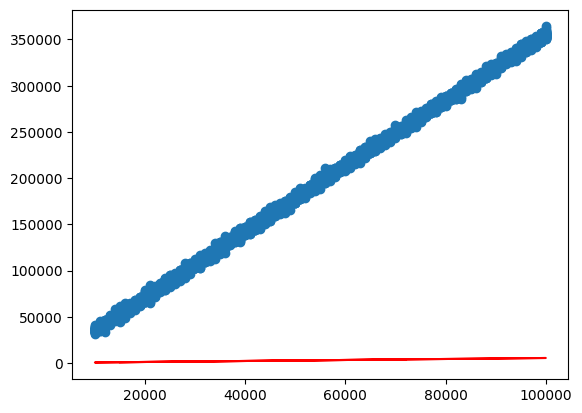

In [ ]:
plt.scatter(X_train, y_train)
plt.plot(X_train, 6.948 + 0.054*X_train, 'r')
plt.show()

## Build Model Scikitlearn

In [ ]:
X2 = df[['tv']]
y2 = df['sales']

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X2, y2, train_size = 0.7, test_size = 0.3, random_state = 100)

In [ ]:
# Create a Linear Regression model
model = LinearRegression()

# Train the model on the training data
model.fit(X_train, y_train)

# Print the intercept and coefficient
print(f"Intercept: {model.intercept_}")
print(f"Coefficient: {model.coef_}")

Intercept: -111.05785004061181
Coefficient: [3.56063267]


In [ ]:
# Predict sales
y_pred = model.predict(X_test)

# Display the first few predictions alongside the actual values
predictions = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})
print(predictions.head())

         Actual      Predicted
2812  130384.13  131632.350916
353   184283.27  185041.840956
3263  288746.34  291860.821037
1907  279665.09  277618.290359
564   226145.13  231330.065658


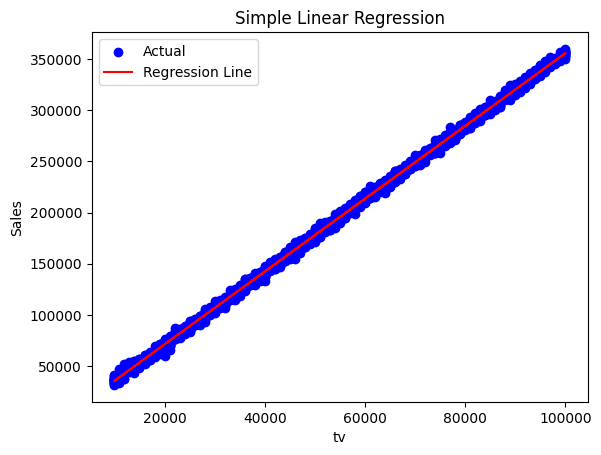

In [ ]:
# Plot the actual data points
plt.scatter(X_test, y_test, color='blue', label='Actual')

# Plot the regression line
plt.plot(X_test, y_pred, color='red', label='Regression Line')

# Add labels and title
plt.xlabel('tv')
plt.ylabel('Sales')
plt.title('Simple Linear Regression')
plt.legend()
plt.show()

## Evaluate Model Statsmodel

In [ ]:
y_train_pred = lr.predict(X_train_sm)
res = (y_train - y_train_pred)

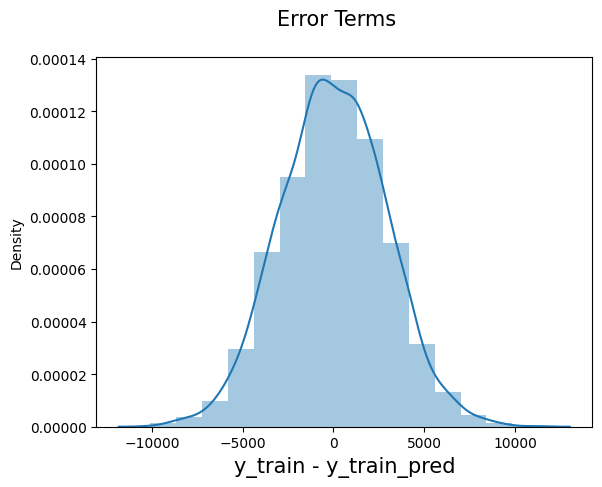

In [ ]:
fig = plt.figure()
sns.distplot(res, bins = 15)
fig.suptitle('Error Terms', fontsize = 15)                  # Plot heading
plt.xlabel('y_train - y_train_pred', fontsize = 15)         # X-label
plt.show()

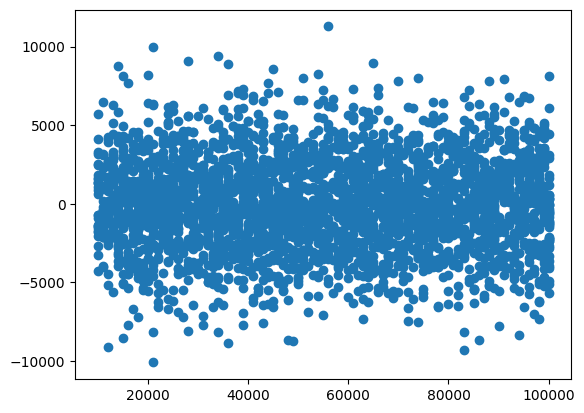

In [ ]:
plt.scatter(X_train,res)
plt.show()

In [ ]:
# Add a constant to X_test
X_test_sm = sm.add_constant(X_test)

# Predict the y values corresponding to X_test_sm
y_pred = lr.predict(X_test_sm)

In [ ]:
# mean squared error

np.sqrt(mean_squared_error(y_test, y_pred))

3044.660048676199

In [ ]:
# R-squared

r_squared = r2_score(y_test, y_pred)
r_squared

0.9989028033017799

## Evaluate Model Scikitlearn

In [ ]:
# Calculate Mean Squared Error (MSE)
mse = mean_squared_error(y_test, y_pred)
print(f"Mean Squared Error: {mse}")

# Calculate R-squared score
r2 = r2_score(y_test, y_pred)
print(f"R-squared score: {r2}")

Mean Squared Error: 9269954.812004955
R-squared score: 0.9989028033017799


MSE adalah pengukuran seberapa dekat garis regresi berada dari data sebenarnya, di mana semakin kecil nilai MSE, semakin baik model dalam memprediksi. Nilai MSE yang cukup rendah ini menunjukkan model regresi yang dibangun memiliki kemampuan prediksi yang baik.

R-squared adalah ukuran seberapa baik model dapat memprediksi nilai-nilai sebenarnya, dengan rentang nilai antara 0 dan 1. Nilai R-squared yang sangat mendekati 1 ini mengindikasikan bahwa model dapat menjelaskan hampir 99,9% dari variasi dalam variabel dependen (konsumsi listrik).

## Logistik Linear

## Building Model

In [ ]:
df['high_sales'] = (df['sales'] > df['sales'].mean()).astype(int)
print("Nilai unik dari kolom 'high_sales':", df['high_sales'].unique())

Nilai unik dari kolom 'high_sales': [0 1]


In [ ]:
# Memastikan bahwa kolom 'high_sales' hanya berisi 0 dan 1
if set(df['high_sales'].unique()) != {0, 1}:
    raise ValueError("Kolom 'high_sales' tidak berisi nilai biner (0 dan 1).")

In [ ]:
# Variabel independen
X = df[['tv', 'radio', 'social_media']]  # Pilih fitur yang relevan
# Variabel dependen
y = df['sales']

In [ ]:
# Splitting Data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
#mengidentifikasi dan membuat daftar kolom-kolom numerik dari dataset X_train
numerical = [col for col in X_train.columns if X_train[col].dtypes != 'O']

numerical

['tv', 'radio', 'social_media']

In [ ]:
X_train[numerical].isnull().sum()

,0
tv,0
radio,0
social_media,0


In [ ]:
X_test[numerical].isnull().sum()

,0
tv,0
radio,0
social_media,0


In [ ]:
# Melatih model regresi logistik
from sklearn.linear_model import LogisticRegression

# Menginstansiasi model
logreg = LogisticRegression(solver='liblinear', random_state=0)

# Melatih model
logreg.fit(X_train, y_train)

LogisticRegression(random_state=0, solver='liblinear')

In [ ]:
# make prediction

y_pred_test = logreg.predict(X_test)

y_pred_test

array([0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,

## Evaluate Model

In [ ]:
from sklearn.metrics import accuracy_score

print('Model accuracy score: {0:0.4f}'. format(accuracy_score(y_test, y_pred_test)))

Model accuracy score: 0.5769


In [ ]:
print('Training set score: {:.4f}'.format(logreg.score(X_train, y_train)))

print('Test set score: {:.4f}'.format(logreg.score(X_test, y_test)))

Training set score: 0.5787
Test set score: 0.5769


Berdasarkan skor model pada set pelatihan dan pengujian yang relatif rendah (di bawah 0.6), dapat disimpulkan bahwa model regresi logistik yang dibangun belum memiliki kinerja yang baik dalam memprediksi target variabel.

In [ ]:
# Confusion Matrix

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_test)

print('Confusion matrix\n\n', cm)

print('\nTrue Positives(TP) = ', cm[0,0])

print('\nTrue Negatives(TN) = ', cm[1,1])

print('\nFalse Positives(FP) = ', cm[0,1])

print('\nFalse Negatives(FN) = ', cm[1,0])

Confusion matrix

 [[ 83 381]
 [  4 442]]

True Positives(TP) =  83

True Negatives(TN) =  442

False Positives(FP) =  381

False Negatives(FN) =  4


Akurasi klasifikasi yang cukup rendah (57.69%)
Precision yang rendah (17.85%), menunjukkan banyak False Positives
Recall yang sangat tinggi (95.35%), menunjukkan model dapat mendeteksi True Positives dengan baik
F1-Score yang rendah (29.75%), mengindikasikan performa model yang belum optimal secara keseluruhan]]

<Axes: >

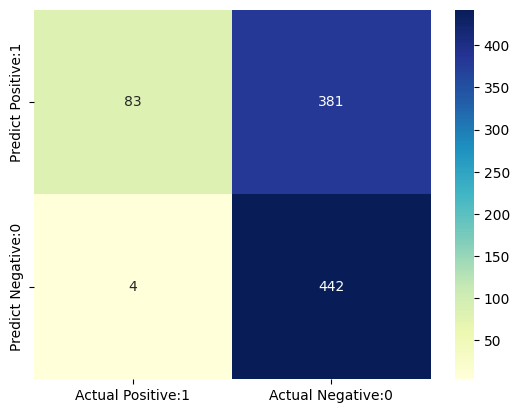

In [ ]:
cm_matrix = pd.DataFrame(data=cm, columns=['Actual Positive:1', 'Actual Negative:0'],
                                 index=['Predict Positive:1', 'Predict Negative:0'])

sns.heatmap(cm_matrix, annot=True, fmt='d', cmap='YlGnBu')

Interpretasi Hasil:
Meskipun model mampu mendeteksi True Positives dengan baik (TP = 83), namun model juga cenderung menghasilkan banyak False Positives (FP = 381).
Hal ini menunjukkan bahwa model belum memiliki performa klasifikasi yang optimal, dengan akurasi yang masih perlu ditingkatkan.

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_test))

              precision    recall  f1-score   support

           0       0.95      0.18      0.30       464
           1       0.54      0.99      0.70       446

    accuracy                           0.58       910
   macro avg       0.75      0.58      0.50       910
weighted avg       0.75      0.58      0.50       910



hasil evaluasi menunjukkan bahwa model memiliki performa yang lebih baik dalam mendeteksi kelas positif (kelas 1), dengan nilai recall yang sangat tinggi (99%). Namun, model masih memiliki kesulitan dalam mengklasifikasikan kelas negatif (kelas 0), ditunjukkan oleh nilai precision, recall, dan F1-score yang rendah untuk kelas 0.
Akurasi keseluruhan model yang hanya 58% juga menunjukkan bahwa model belum dapat memberikan hasil klasifikasi yang memuaskan.

In [ ]:
TP = cm[0,0]
TN = cm[1,1]
FP = cm[0,1]
FN = cm[1,0]

In [ ]:
classification_accuracy = (TP + TN) / float(TP + TN + FP + FN)
print('Classification accuracy : {0:0.4f}'.format(classification_accuracy))

Classification accuracy : 0.5769


In [ ]:
classification_error = (FP + FN) / float(TP + TN + FP + FN)
print('Classification error : {0:0.4f}'.format(classification_error))

Classification error : 0.4231


In [ ]:
precision = TP / float(TP + FP)
print('Precision : {0:0.4f}'.format(precision))

Precision : 0.1789


In [ ]:
recall = TP / float(TP + FN)
print('Recall or Sensitivity : {0:0.4f}'.format(recall))

Recall or Sensitivity : 0.9540


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4546 entries, 0 to 4545
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   tv            4546 non-null   float64
 1   radio         4546 non-null   float64
 2   social_media  4546 non-null   float64
 3   sales         4546 non-null   float64
 4   high_sales    4546 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 177.7 KB


<Axes: xlabel='sales', ylabel='count'>

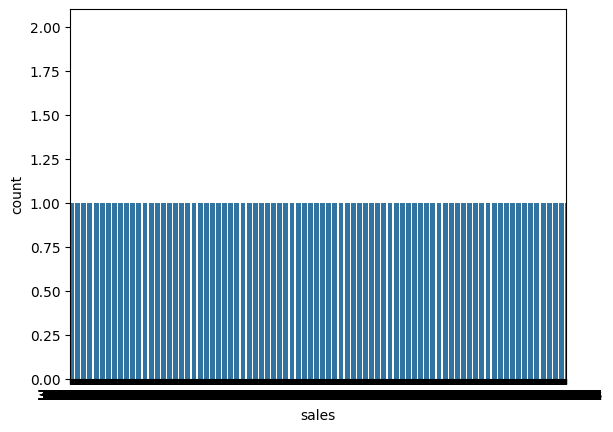

In [ ]:
sns.countplot(x='sales', data=df)

## Data Processing

In [ ]:
# Check if 'sales' is in the list before removing it.
if 'sales' in categorical_col:
    categorical_col.remove('sales')
else:
    print("'sales' is not in the list, skipping removal.")

'sales' is not in the list, skipping removal.


In [ ]:
categorical_col.remove('sales')

ValueError: list.remove(x): x not in list